In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error


In [2]:
df = pd.read_csv("/content/uber.csv")

In [3]:
df = df.dropna()
df = df.drop_duplicates()


In [4]:
df = df[df['fare_amount'] > 0]

df = df[df['passenger_count'] > 0]


In [5]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[
    (df['fare_amount'] >= lower) &
    (df['fare_amount'] <= upper)
]

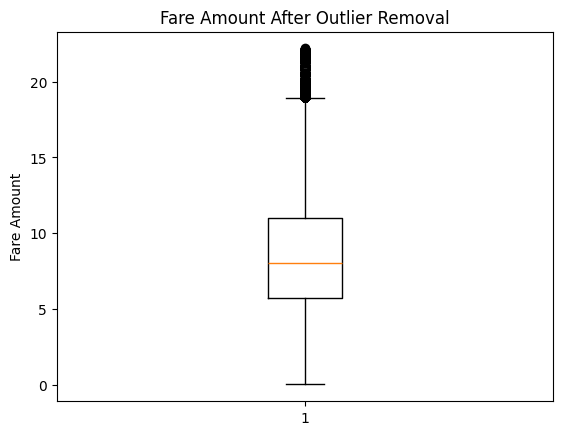

In [6]:
plt.boxplot(df['fare_amount'])
plt.title("Fare Amount After Outlier Removal")
plt.ylabel("Fare Amount")
plt.show()


In [7]:
print("Correlation with Fare Amount:")
print(df.corr(numeric_only=True)['fare_amount'])

Correlation with Fare Amount:
Unnamed: 0           0.003606
fare_amount          1.000000
pickup_longitude    -0.003046
pickup_latitude      0.005499
dropoff_longitude   -0.005075
dropoff_latitude     0.001948
passenger_count      0.013416
Name: fare_amount, dtype: float64


In [8]:
X = df[['pickup_longitude', 'pickup_latitude',
        'dropoff_longitude', 'dropoff_latitude',
        'passenger_count']]

In [9]:
y = df['fare_amount']

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [11]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01)
}

In [12]:
for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    rmse = mean_squared_error(y_test, y_pred) ** 0.5

    print("\n", name)
    print("R2 Score:", r2)
    print("RMSE:", rmse)


 Linear Regression
R2 Score: -0.0013197947888656802
RMSE: 4.135914013408009

 Ridge Regression
R2 Score: -0.0013197841887104822
RMSE: 4.135913991516236

 Lasso Regression
R2 Score: -0.0007207029118112551
RMSE: 4.134676564977129


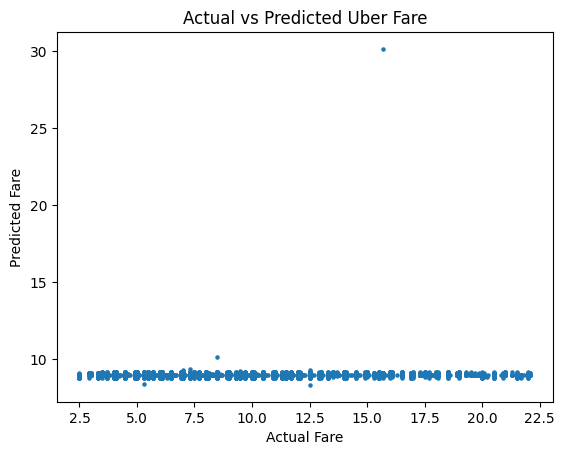

In [13]:
plt.scatter(y_test, y_pred, s=5)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Uber Fare")
plt.show()